# TP  1: Cadrage BI, processus métier et découverte des sources

**objectif**

Formaliser le besoin, les questions décisionnelles, le processus
principal et les sources.

In [1]:
import pandas as pd
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/xxxxxcn/uci-online-retail-original-workbook/Online Retail.xlsx
/kaggle/input/datasets/xxxxxcn/uci-online-retail-original-workbook/README.md


In [2]:
import pandas as pd
df = pd.read_excel("/kaggle/input/datasets/xxxxxcn/uci-online-retail-original-workbook/Online Retail.xlsx")

* ## 1 Question de depart 

Pour passer d’un besoin de pilotage à des sources exploitables, on part de ce que la direction veut comprendre sur son activité de vente, puis on le transforme en questions précises portant sur ce qu’un décideur cherche dans les données (ventes, produits, pays, clients). On vérifie ensuite que l’historique UCI Online Retail contient réellement les informations nécessaires, et on reformule toute question qui ne peut pas être alimentée plutôt que d’inventer une donnée.

* ## 2 comment allez vous raisonner ?

**--> Que devons nous etre capables de decider ou comprendre ?**

Nous devons être capables de comprendre comment se comporte l’activité de vente de l’entreprise : à quels moments elle est forte ou faible, quels produits et quels pays portent le chiffre d’affaires, et quelle part des ventes provient de clients identifiés. Ces constats doivent permettre à la direction d’orienter ses décisions, par exemple sur les produits à mettre en avant, les marchés à privilégier et le suivi de la clientèle.

**--> Quelles est le processus métier observable dans le fichier ?**

- Une vente est enregistrée sous forme de facture, identifiée par InvoiceNo.
- Chaque facture porte la date et l’heure exactes de la vente (InvoiceDate).
- Elle contient une ou plusieurs lignes de produits : chaque produit est identifié par StockCode et décrit par description, avec une quantité vendue (Quantity) et un prix unitaire (UnitPrice).
- La vente est associée à un pays (Country).
- Elle est rattachée à un client identifié par CustomerID, ou à un client inconnu lorsque cette information est absente.
- Les étapes comme le paiement, la livraison ou la gestion du stock ne figurent pas dans le fichier, donc elles ne sont pas représentées.

**-->Quelle limite de la source devez-vous signaler ?**

- Aucune information sur le paiement (mode, date, validation) : on ne peut pas savoir si une vente a été réellement payée.
- Aucune information sur le stock (quantité en stock, statut de chaque produit) : StockCode identifie seulement le produit.
- La période couverte est courte, donc on ne peut pas comparer les ventes de fin d’année avec celles de l’année précédente.
- Il n’y a pas de colonne « mois » ou « année » : elles doivent être déduites de InvoiceDate, et l’analyse mensuelle n’est possible que sur la période couverte.
- Des valeurs manquantes existent, notamment pour CustomerID  et Description, ce qui limite les analyses sur les clients.
- Une valeur manquante n’est pas forcément une erreur : elle peut correspondre à une vente sans client identifié.
Le fichier peut contenir des valeurs atypiques (quantités négatives, prix à zéro), à vérifier plus tard sans les corriger dans ce TP.
 

**-->Quelles questions peuvent être mesurées avec la source ?**

- Quel produit se vend le plus dans certains pays ? 
- Quels pays contribuent le plus aux ventes ? 
- Combien de clients sont réguliers ? 
- Les ventes augmentent-elles au fil du temps ? 

**-->Quels champs semblent nécessaires pour répondre aux questions ?**

* **InvoiceNo** : identifie chaque facture (commande). Il sert à compter les commandes et les factures par client.
* **StockCode** : identifie le produit. Il sert à savoir quel produit se vend le plus.
* **Description** : décrit le produit. Il rend les résultats lisibles pour le décideur.
* **Quantity** : quantité vendue. Elle mesure le volume des ventes.
* **InvoiceDate** : date et heure de la facture. Elle sert à suivre l’évolution des ventes dans le temps (par mois, par période).
* **UnitPrice** : prix unitaire. Avec Quantity, il permet de calculer le chiffre d’affaires (Quantity × UnitPrice).
* **CustomerID** : identifie le client. Il sert à repérer les clients réguliers et à distinguer clients identifiés et inconnus.
* **Country** : pays de la vente. Il sert à comparer les pays et à voir quels produits se vendent le plus dans chacun.

**-->Comment vérifierez-vous que votre inventaire est fidèle au fichier
?**

- on charge le fichier compare avec la liste des 8 colonnes sur lesquelles je dois travailler 

 ## 1.  Charger et inspecter la source 

In [3]:
## les dimensison de dataset 
df.shape 

(541909, 8)

In [4]:
## les colonnes presents 
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [5]:
## les premiersligne 
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
## infos sur les lignes et types  et colonnes 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### ---> on remarque que il ya des valeurs manquants pour "description" et "custumerID"

In [7]:
## nombres de valeurs null
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
## observations des doublons parmi 541909 lignes 
df.duplicated().sum()

np.int64(5268)

In [9]:
## nombres des lignes distincts 
df_sans_doublons = df[~df.duplicated()]
print(df_sans_doublons.shape)

(536641, 8)


In [10]:
## informations resumés de statistiques numériques 
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303



**Quelles informations sont réellement disponibles et lesquelles nedoivent pas être inventées ?**

- qui achète:< custumerID >
- quoi : < Description >
- combien : < quantity >
- prix : < unit price > 
- quand : < invoicedate >
- ou : < pays >
- Quelle commande : < invoiceNo (la facture) >

**>> informations a ne pas inventé :**
  - mode paiment
  - date livraison
  - quantité de stock restant
  - canal de vente 

## 2. Profiler les champs utiles au cadrage

### Tableau de profilage :

In [11]:

profil = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "nb_manquants": df.isnull().sum(),
    "pct_manquants": (df.isnull().mean() * 100).round(2),
    "nb_distincts": df.nunique(),
})

# min et max : uniquement Quantity, UnitPrice, InvoiceDate
cols = ["Quantity", "UnitPrice", "InvoiceDate"]
profil["min"] = df[cols].min()
profil["max"] = df[cols].max()

# négatifs et zéros : uniquement Quantity et UnitPrice
num = df[["Quantity", "UnitPrice"]]
profil["nb_negatifs"] = (num < 0).sum()
profil["nb_zeros"] = (num == 0).sum()

# un exemple de valeur par colonne
profil["exemple"] = df.iloc[0].astype(str)

display(profil)

,type,nb_manquants,pct_manquants,nb_distincts,min,max,nb_negatifs,nb_zeros,exemple
InvoiceNo,object,0,0.00,25900,NaN,NaN,NaN,NaN,536365
StockCode,object,0,0.00,4070,NaN,NaN,NaN,NaN,85123A
Description,object,1454,0.27,4223,NaN,NaN,NaN,NaN,WHITE HANGING HEART T-LIGHT HOLDER
Quantity,int64,0,0.00,722,-80995,80995,10624.0,0.0,6
InvoiceDate,datetime64[ns],0,0.00,23260,2010-12-01 08:26:00,2011-12-09 12:50:00,NaN,NaN,2010-12-01 08:26:00
UnitPrice,float64,0,0.00,1630,-11062.06,38970.0,2.0,2515.0,2.55
CustomerID,float64,135080,24.93,4372,NaN,NaN,NaN,NaN,17850.0
Country,object,0,0.00,38,NaN,NaN,NaN,NaN,United Kingdom


**Une valeur manquante est-elle automatiquement une erreur métier ?**

Non. Une valeur manquante n’est pas automatiquement une erreur métier : tout dépend de ce qu’elle représente dans le processus de vente.

> * **CustomerID manquant** : il correspond très probablement à une vente sans client identifié (achat sans compte client). Ce n’est donc pas une erreur, mais une information métier : ces ventes existent bel et bien et restent valables pour analyser les produits, les pays et le temps. En revanche, elles ne peuvent pas être rattachées à un client précis. Dans mes observations, ce champ concentre la plus grande part des valeurs manquantes [26 %].
> 
>  * **Description manquante** : elle est plus probablement un défaut de saisie ou de qualité, car un produit vendu devrait avoir un libellé. Mais le produit reste identifiable par StockCode, donc la ligne n’est pas forcément inutilisable.


Dans les deux cas, on documente le constat et on évalue son impact sur les questions décisionnelles, sans corriger les données dans ce TP. Le traitement (garder, remplacer ou exclure) sera décidé en TP2.

## 3. Relier les champs au processus de vente

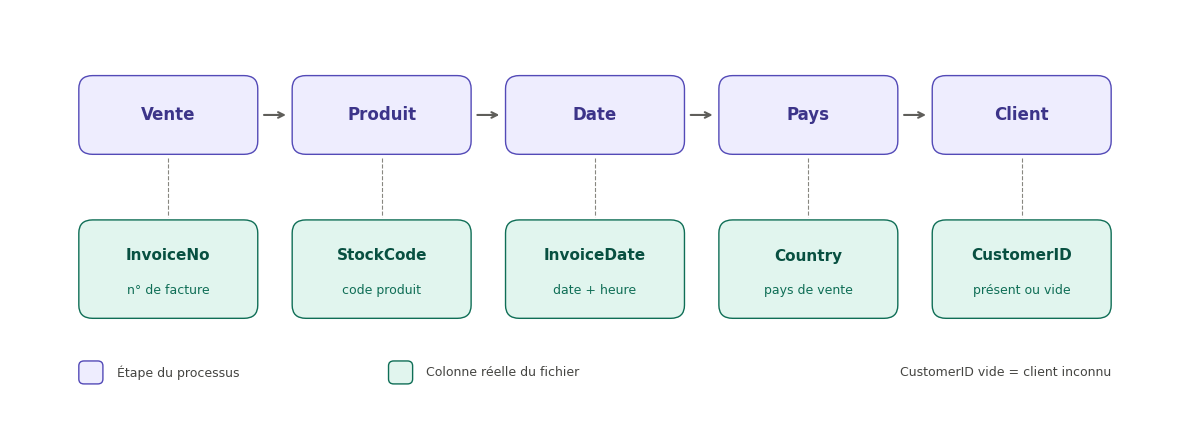

In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# (étape, colonne réelle, description courte)
etapes = [
    ("Vente",   "InvoiceNo",   "n° de facture"),
    ("Produit", "StockCode",   "code produit"),
    ("Date",    "InvoiceDate", "date + heure"),
    ("Pays",    "Country",     "pays de vente"),
    ("Client",  "CustomerID",  "présent ou vide"),
]

# Couleurs (violet = étape, vert = colonne)
VIOLET_FOND, VIOLET_BORD, VIOLET_TXT = "#EEEDFE", "#534AB7", "#3C3489"
VERT_FOND, VERT_BORD, VERT_TXT, VERT_SOUS = "#E1F5EE", "#0F6E56", "#085041", "#0F6E56"

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.set_xlim(0, 680)
ax.set_ylim(250, 0)      # axe y inversé : le haut du schéma est en haut
ax.axis("off")

W, GAP, X0 = 104, 20, 40

for i, (etape, colonne, desc) in enumerate(etapes):
    x = X0 + i * (W + GAP)
    cx = x + W / 2

    # Rangée du haut : étape du processus
    ax.add_patch(FancyBboxPatch((x, 40), W, 48,
                 boxstyle="round,pad=0,rounding_size=8",
                 fc=VIOLET_FOND, ec=VIOLET_BORD, lw=1))
    ax.text(cx, 64, etape, ha="center", va="center",
            fontsize=12, fontweight="bold", color=VIOLET_TXT)

    # Flèche vers l'étape suivante
    if i < len(etapes) - 1:
        ax.annotate("", xy=(x + W + GAP - 2, 64), xytext=(x + W + 2, 64),
                    arrowprops=dict(arrowstyle="->", color="#5F5E5A", lw=1.5))

    # Trait pointillé étape -> colonne
    ax.plot([cx, cx], [90, 126], ls="--", lw=0.8, color="#888780")

    # Rangée du bas : colonne réelle du fichier
    ax.add_patch(FancyBboxPatch((x, 128), W, 60,
                 boxstyle="round,pad=0,rounding_size=8",
                 fc=VERT_FOND, ec=VERT_BORD, lw=1))
    ax.text(cx, 150, colonne, ha="center", va="center",
            fontsize=11, fontweight="bold", color=VERT_TXT)
    ax.text(cx, 171, desc, ha="center", va="center",
            fontsize=9, color=VERT_SOUS)

# Légende
ax.add_patch(FancyBboxPatch((40, 214), 14, 14, boxstyle="round,pad=0,rounding_size=3",
             fc=VIOLET_FOND, ec=VIOLET_BORD, lw=1))
ax.text(62, 221, "Étape du processus", va="center", fontsize=9, color="#444441")

ax.add_patch(FancyBboxPatch((220, 214), 14, 14, boxstyle="round,pad=0,rounding_size=3",
             fc=VERT_FOND, ec=VERT_BORD, lw=1))
ax.text(242, 221, "Colonne réelle du fichier", va="center", fontsize=9, color="#444441")

ax.text(640, 221, "CustomerID vide = client inconnu",
        ha="right", va="center", fontsize=9, color="#444441")

plt.tight_layout()
plt.savefig("processus_vente.png", dpi=200, bbox_inches="tight")  # pour l'insérer dans L1
plt.show()

Une vente est reliée à un produit, une date, un pays et un client, identifié ou inconnu ; le grain du futur fait n’est pas fixé à ce stade.

**Quelle information permet d’identifier une commande et quelle
information décrit le produit?**

> * Identifier une commande : la colonne InvoiceNo (numéro de facture). Une même facture peut contenir plusieurs lignes, c’est-à-dire plusieurs produits.
>   
> * Décrire le produit : la colonne Description (libellé du produit), accompagnée de StockCode qui l’identifie. Quantity et UnitPrice précisent la quantité vendue et le prix.





## 4. Questions décisionnelles :

**QUESTION 1 :**

- Comment le chiffre d’affaires évolue-t-il d’un mois à l’autre, et quelles sont les périodes de forte ou de faible activité ?

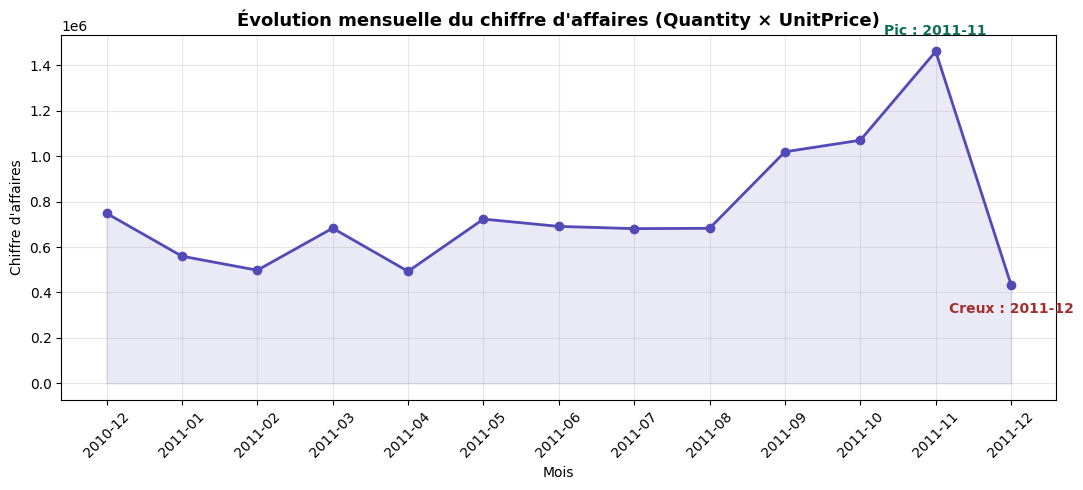

In [13]:
import matplotlib.pyplot as plt

# Calcul sur une copie des colonnes utiles : df n'est pas modifié
ventes = df[["InvoiceDate", "Quantity", "UnitPrice"]].copy()
ventes["CA"] = ventes["Quantity"] * ventes["UnitPrice"]
ventes["Mois"] = ventes["InvoiceDate"].dt.to_period("M")

ca_mensuel = ventes.groupby("Mois")["CA"].sum()
ca_mensuel.index = ca_mensuel.index.astype(str)   # étiquettes lisibles

# Courbe
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(ca_mensuel.index, ca_mensuel.values, marker="o", lw=2, color="#534AB7")
ax.fill_between(ca_mensuel.index, ca_mensuel.values, alpha=0.12, color="#534AB7")

# Repérer le pic et le creux
mois_max, mois_min = ca_mensuel.idxmax(), ca_mensuel.idxmin()
ax.annotate(f"Pic : {mois_max}", (mois_max, ca_mensuel.max()),
            textcoords="offset points", xytext=(0, 12), ha="center",
            color="#0F6E56", fontweight="bold")
ax.annotate(f"Creux : {mois_min}", (mois_min, ca_mensuel.min()),
            textcoords="offset points", xytext=(0, -20), ha="center",
            color="#A32D2D", fontweight="bold")

ax.set_title("Évolution mensuelle du chiffre d'affaires (Quantity × UnitPrice)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("courbe_ca_mensuel.png", dpi=200, bbox_inches="tight")
plt.show()

**QUESTION 2 :**

- Quels produits génèrent la plus grande part des ventes (en quantité et en chiffre d’affaires) ? 

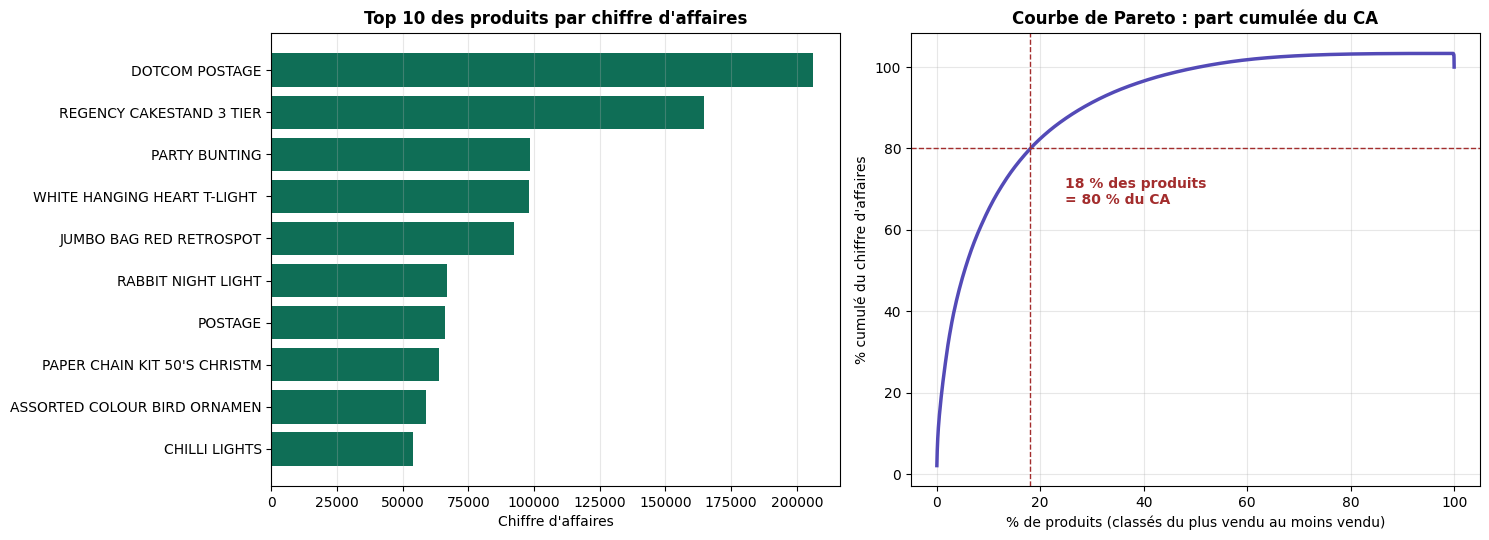

737 produits sur 4070 (18.1 %) réalisent 80 % du CA


In [14]:
import matplotlib.pyplot as plt

# Calcul sur une copie : df n'est pas modifié
ventes = df[["StockCode", "Description", "Quantity", "UnitPrice"]].copy()
ventes["CA"] = ventes["Quantity"] * ventes["UnitPrice"]

# CA par produit (StockCode), classé du plus grand au plus petit
ca_produit = ventes.groupby("StockCode")["CA"].sum().sort_values(ascending=False)

# Libellé lisible : la Description la plus fréquente de chaque StockCode
libelle = (ventes.dropna(subset=["Description"])
                 .groupby("StockCode")["Description"]
                 .agg(lambda s: s.mode().iloc[0]))

# Part cumulée du CA
part_cumulee = ca_produit.cumsum() / ca_produit.sum() * 100
rang_pct = (range(1, len(ca_produit) + 1))
rang_pct = [r / len(ca_produit) * 100 for r in rang_pct]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Graphique 1 : top 10 produits par CA
top10 = ca_produit.head(10)
noms = [str(libelle.get(c, c))[:28] for c in top10.index]
ax1.barh(noms[::-1], top10.values[::-1], color="#0F6E56")
ax1.set_title("Top 10 des produits par chiffre d'affaires", fontweight="bold")
ax1.set_xlabel("Chiffre d'affaires")
ax1.grid(axis="x", alpha=0.3)

# Graphique 2 : courbe de Pareto
ax2.plot(rang_pct, part_cumulee.values, color="#534AB7", lw=2.5)
ax2.axhline(80, color="#A32D2D", ls="--", lw=1)
n80 = int((part_cumulee < 80).sum()) + 1
pct80 = n80 / len(ca_produit) * 100
ax2.axvline(pct80, color="#A32D2D", ls="--", lw=1)
ax2.annotate(f"{pct80:.0f} % des produits\n= 80 % du CA",
             (pct80, 80), textcoords="offset points", xytext=(25, -40),
             color="#A32D2D", fontweight="bold")
ax2.set_title("Courbe de Pareto : part cumulée du CA", fontweight="bold")
ax2.set_xlabel("% de produits (classés du plus vendu au moins vendu)")
ax2.set_ylabel("% cumulé du chiffre d'affaires")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("courbe_pareto_produits.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"{n80} produits sur {len(ca_produit)} ({pct80:.1f} %) réalisent 80 % du CA")

**QUESTION 3:**

- Quels pays contribuent le plus au chiffre d’affaires, et quel est le poids du premier pays par rapport aux autres ?

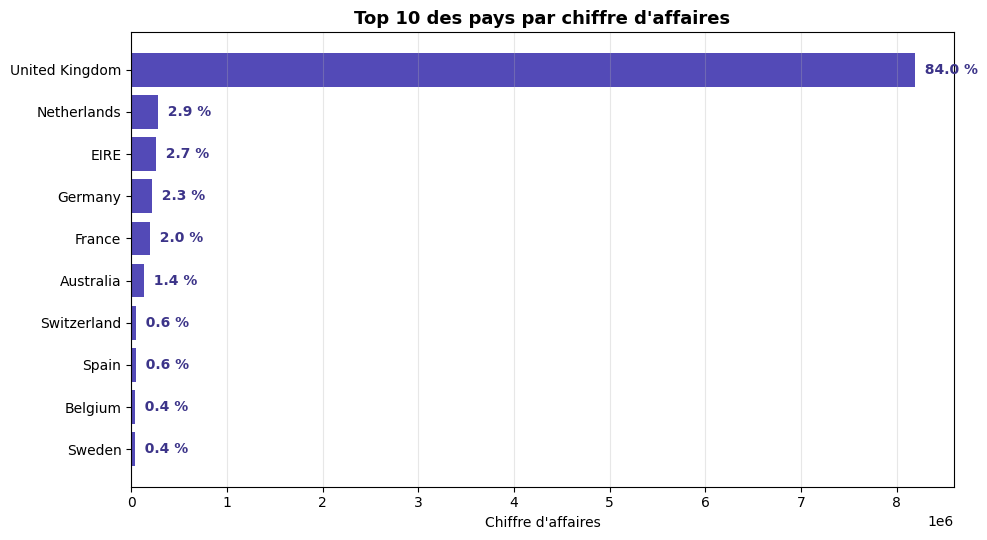

Premier pays : United Kingdom = 84.0 % du chiffre d'affaires
Nombre de pays dans le fichier : 38


In [15]:
import matplotlib.pyplot as plt

# Calcul sur une copie : df n'est pas modifié
ventes = df[["Country", "Quantity", "UnitPrice"]].copy()
ventes["CA"] = ventes["Quantity"] * ventes["UnitPrice"]

ca_pays = ventes.groupby("Country")["CA"].sum().sort_values(ascending=False)
part_pays = ca_pays / ca_pays.sum() * 100

# Top 10 pays
top10 = ca_pays.head(10)
part10 = part_pays.head(10)

fig, ax = plt.subplots(figsize=(10, 5.5))
barres = ax.barh(top10.index[::-1], top10.values[::-1], color="#534AB7")

# Écrire le pourcentage au bout de chaque barre
for barre, p in zip(barres, part10.values[::-1]):
    ax.text(barre.get_width(), barre.get_y() + barre.get_height() / 2,
            f"  {p:.1f} %", va="center", fontweight="bold", color="#3C3489")

ax.set_title("Top 10 des pays par chiffre d'affaires", fontsize=13, fontweight="bold")
ax.set_xlabel("Chiffre d'affaires")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("pays_ca.png", dpi=200, bbox_inches="tight")
plt.show()

premier = ca_pays.index[0]
print(f"Premier pays : {premier} = {part_pays.iloc[0]:.1f} % du chiffre d'affaires")
print(f"Nombre de pays dans le fichier : {len(ca_pays)}")

**QUESTION 4:**

- Quelle part des ventes provient de clients identifiés par rapport aux clients inconnus, et combien de produits contient une commande en moyenne ?

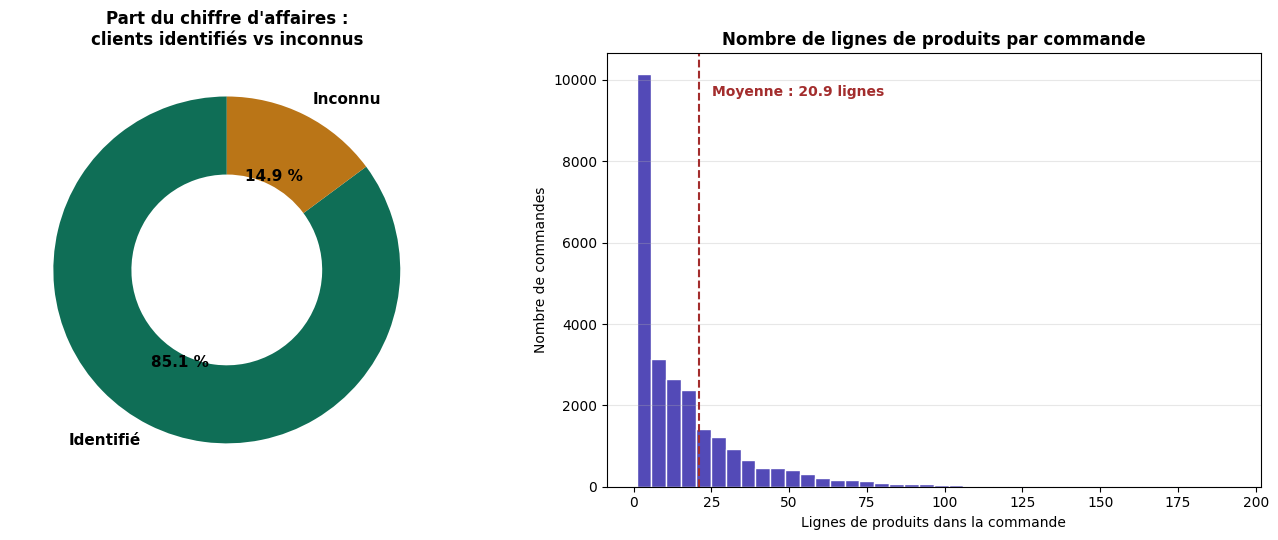

Part des lignes (%) :
Client
Identifié    75.1
Inconnu      24.9
Name: proportion, dtype: float64

Part du CA (%) :
Client
Identifié    85.1
Inconnu      14.9
Name: CA, dtype: float64

Nombre de commandes : 25900
Moyenne de lignes par commande : 20.9
Médiane : 10


In [16]:
import matplotlib.pyplot as plt

# Calcul sur une copie : df n'est pas modifié
d = df[["InvoiceNo", "CustomerID", "Quantity", "UnitPrice"]].copy()
d["CA"] = d["Quantity"] * d["UnitPrice"]
d["Client"] = d["CustomerID"].notna().map({True: "Identifié", False: "Inconnu"})

# Partie 1 : part des lignes et du CA selon client identifié / inconnu
part_lignes = d["Client"].value_counts(normalize=True) * 100
part_ca = d.groupby("Client")["CA"].sum() / d["CA"].sum() * 100

# Partie 2 : nombre de lignes de produits par commande (par facture)
lignes_par_commande = d.groupby("InvoiceNo").size()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Graphique 1 : anneau de la part du CA
couleurs = {"Identifié": "#0F6E56", "Inconnu": "#BA7517"}
ax1.pie(part_ca.values, labels=part_ca.index, autopct="%1.1f %%",
        startangle=90, wedgeprops=dict(width=0.45),
        colors=[couleurs[c] for c in part_ca.index],
        textprops=dict(fontsize=11, fontweight="bold"))
ax1.set_title("Part du chiffre d'affaires :\nclients identifiés vs inconnus", fontweight="bold")

# Graphique 2 : histogramme du nombre de lignes par commande
limite = int(lignes_par_commande.quantile(0.99))
ax2.hist(lignes_par_commande[lignes_par_commande <= limite],
         bins=40, color="#534AB7", edgecolor="white")
ax2.axvline(lignes_par_commande.mean(), color="#A32D2D", ls="--", lw=1.5)
ax2.annotate(f"Moyenne : {lignes_par_commande.mean():.1f} lignes",
             (lignes_par_commande.mean(), ax2.get_ylim()[1] * 0.9),
             xytext=(10, 0), textcoords="offset points",
             color="#A32D2D", fontweight="bold")
ax2.set_title("Nombre de lignes de produits par commande", fontweight="bold")
ax2.set_xlabel("Lignes de produits dans la commande")
ax2.set_ylabel("Nombre de commandes")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("question4_clients_commandes.png", dpi=200, bbox_inches="tight")
plt.show()

print("Part des lignes (%) :")
print(part_lignes.round(1))
print("\nPart du CA (%) :")
print(part_ca.round(1))
print(f"\nNombre de commandes : {len(lignes_par_commande)}")
print(f"Moyenne de lignes par commande : {lignes_par_commande.mean():.1f}")
print(f"Médiane : {lignes_par_commande.median():.0f}")

## 5. Analyse et intérprétation :

**Observation :**

ce que les données montrent réellement

> * Le fichier contient **541909** lignes et **8** colonnes, qui correspondent bien aux colonnes attendues.
> * **CustomerID** est manquant dans **26%** des lignes, et **Description** dans **0,47%** lignes. Les autres colonnes sont complètes.
> * La période couverte va du **2021-12** au **2011-12**.
> * Des **quantités négatives**, des **prix à zéro** et des factures commençant par **« C » (annulations)** sont présents.
> * Le chiffre d’affaires est concentré sur **UK (80%)** et sur un petit nombre de produits.
> * Le chiffre d’affaires mensuel présente un pic en **Novembre** et un creux en **decembre**.


**Analyse :** 

ce que ces observations impliquent pour le cadrage

> * Les huit colonnes suffisent pour répondre aux quatre questions décisionnelles (temps, produits, pays, commandes/clients).
> * Les analyses sur les clients ne couvrent que les ventes dont CustomerID est renseigné.
> * Une valeur manquante n’est pas forcément une erreur : un CustomerID vide correspond probablement à une vente sans client identifié.
> * Les quantités négatives et les annulations rendent le chiffre d’affaires « brut », donc à interpréter avec prudence.
> * La période est d’environ 6 mois, donc la comparaison d’une année sur l’autre est impossible, et le dernier mois est peut-être incomplet.
> * Le fichier ne contient ni paiement, ni stock, ni coût, ni marge, ni catégorie de produit.


**Interprétation :**

ce que cela signifie pour l’équipe BI


> * La source est exploitable pour analyser les ventes (évolution, produits, pays, commandes), mais pas pour piloter la rentabilité, le stock ou les paiements.
> * Les résultats sur les clients devront toujours préciser qu’ils portent sur les clients identifiés uniquement.
> * Les chiffres actuels sont des constats bruts : ils ne doivent pas encore servir à prendre une décision tant que les anomalies n’ont pas été traitées.
> * Les décisions de traitement (garder, corriger ou exclure) ne sont pas prises ici : elles relèvent de TP2.


**Décision :**

éléments de L1 retenus pour la suite:

> * Les quatre questions décisionnelles, toutes reliées à au moins une colonne réelle.
> * L’inventaire des huit colonnes et le tableau de profilage.
> * Le processus de vente : vente → produit → date → pays → client identifié/inconnu.
> * La liste des limites de la source : valeurs manquantes, annulations, quantités négatives, prix à zéro, période courte, informations absentes.
> * Les points à auditer en TP2 : CustomerID manquant, factures « C », quantités négatives, prix à zéro et libellés de Description non uniformes.
